In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import kagglehub
import os

In [ ]:
path = kagglehub.dataset_download("excel4soccer/espn-soccer-data")

Using Colab cache for faster access to the 'espn-soccer-data' dataset.


**Research question**

Do home teams keep clean sheets at a significantly higher rate than away teams?

**Null & Alternative Hypothesis**

- $H_0$ (Null Hypothesis): $p_{\text{home}} = p_{\text{away}}$ (Clean sheet rate is equal between home and away teams)
- $H_1$ (Alternative Hypothesis): $p_{\text{home}} > p_{\text{away}}$ (Home teams have a significantly higher clean sheet rate)

**Reading in CSV File**

In [ ]:
# List all files in the downloaded dataset path
if os.path.exists(path):
    files = os.listdir(path)
    print("Files in dataset folder:", files)
else:
    print("Dataset path not found. Please make sure the previous download step ran successfully.")

Files in dataset folder: ['plays_data', 'base_data', 'lineup_data', 'keyEvents_data', 'commentary_data', 'playerStats_data']


In [ ]:
base_data_path = os.path.join(path, 'base_data')

# Load the fixtures.csv which contains match scores and home/away teams
fixtures_path = os.path.join(base_data_path, 'fixtures.csv')
soccer_data = pd.read_csv(fixtures_path)
soccer_data.head()

,Rn,seasonType,leagueId,eventId,date,venueId,attendance,homeTeamId,awayTeamId,homeTeamWinner,awayTeamWinner,homeTeamScore,awayTeamScore,homeTeamShootoutScore,awayTeamShootoutScore,statusId,updateTime
0,1,12136,3922,689519,2024-01-01 05:00:00,8680,61916,627,4396,True,False,5,0,0,0,28,2024-01-07 03:20:23
1,2,12136,3922,694555,2024-01-01 13:30:00,4775,0,658,1928,False,True,1,2,0,0,28,2024-01-07 03:20:24
2,3,12136,3922,693431,2024-01-02 13:00:00,7614,0,4895,2621,False,True,0,4,0,0,28,2024-01-07 03:20:59
3,4,12136,3922,694586,2024-01-04 12:00:00,9877,0,1928,6723,False,True,1,2,0,0,28,2024-01-07 03:21:28
4,5,12136,3922,690701,2024-01-04 13:30:00,9876,0,655,4388,True,False,1,0,0,0,28,2024-01-07 03:21:29


**Data Cleaning**

In [ ]:
# A home team keeps a clean sheet if the away team scores 0
soccer_data['home_clean_sheet'] = (soccer_data['awayTeamScore'] == 0).astype(int)

# An away team keeps a clean sheet if the home team scores 0
soccer_data['away_clean_sheet'] = (soccer_data['homeTeamScore'] == 0).astype(int)

# Let's keep only the columns relevant to our research question to keep things clean
cleaned_soccer = soccer_data[['homeTeamId', 'awayTeamId', 'homeTeamScore', 'awayTeamScore', 'home_clean_sheet', 'away_clean_sheet']].copy()
cleaned_soccer.head()

,homeTeamId,awayTeamId,homeTeamScore,awayTeamScore,home_clean_sheet,away_clean_sheet
0,627,4396,5,0,1,0
1,658,1928,1,2,0,0
2,4895,2621,0,4,0,1
3,1928,6723,1,2,0,0
4,655,4388,1,0,1,0


**Data Visualizations**

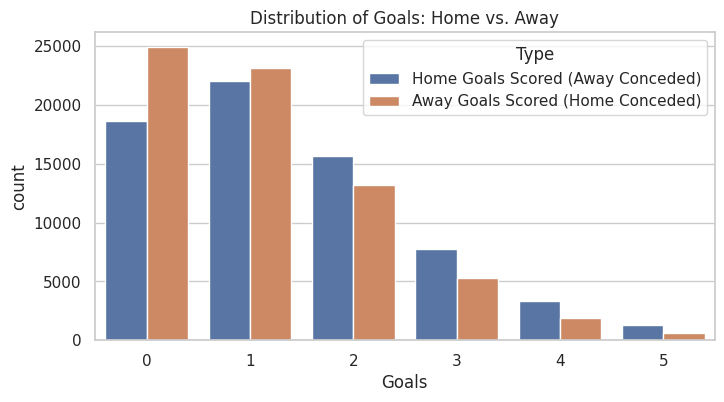

In [ ]:
plt.figure(figsize=(8, 4))
sns.countplot(
    data=goals_df,
    x='Goals',
    hue='Type'
)
plt.title('Distribution of Goals: Home vs. Away')
plt.xlim(-0.5, 5.5)
plt.show()

Home Clean Sheet Rate: 0.3593 (approx. 35.9%)
Away Clean Sheet Rate: 0.2681 (approx. 26.8%)


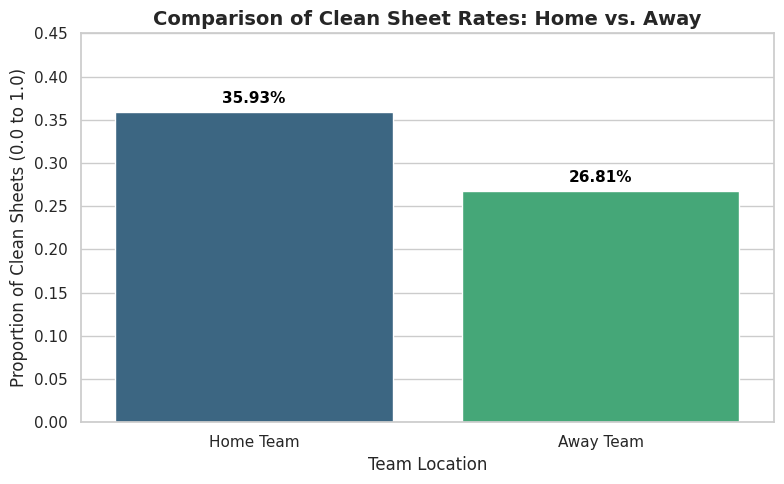

In [ ]:
# Calculate overall clean sheet rates
home_rate = cleaned_soccer['home_clean_sheet'].mean()
away_rate = cleaned_soccer['away_clean_sheet'].mean()

print(f"Home Clean Sheet Rate: {home_rate:.4f} (approx. {home_rate*100:.1f}%)")
print(f"Away Clean Sheet Rate: {away_rate:.4f} (approx. {away_rate*100:.1f}%)")

# --- GRAPH 1: Comparison of Clean Sheet Rates ---
plt.figure(figsize=(8, 5))
rates_df = pd.DataFrame({
    'Team Type': ['Home Team', 'Away Team'],
    'Clean Sheet Rate': [home_rate, away_rate]
})

sns.barplot(
    data=rates_df,
    x='Team Type',
    y='Clean Sheet Rate',
    hue='Team Type',
    palette='viridis',
    legend=False
)
plt.title('Comparison of Clean Sheet Rates: Home vs. Away', fontsize=14, fontweight='bold')
plt.ylabel('Proportion of Clean Sheets (0.0 to 1.0)', fontsize=12)
plt.xlabel('Team Location', fontsize=12)
plt.ylim(0, 0.45)

# Add values on top of the bars
for index, row in rates_df.iterrows():
    plt.text(index, row['Clean Sheet Rate'] + 0.01, f"{row['Clean Sheet Rate']*100:.2f}%", color='black', ha="center", fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

**Hypothesis Testing**

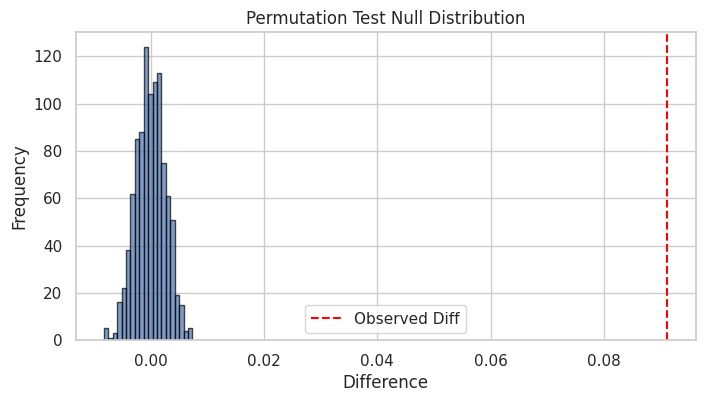

In [ ]:
plt.figure(figsize=(8, 4))
plt.hist(simulated_diffs, bins=20, edgecolor='black', alpha=0.7)
plt.axvline(observed_diff, color='red', linestyle='dashed', label='Observed Diff')
plt.title('Permutation Test Null Distribution')
plt.xlabel('Difference')
plt.ylabel('Frequency')
plt.legend()
plt.show()

In [ ]:
# 1. Calculate the observed difference
# (Home Clean Sheet Rate - Away Clean Sheet Rate)
observed_diff = home_rate - away_rate
print(f"Observed Difference in Clean Sheet Rates: {observed_diff:.4f}")

# 2. To perform a simulation/permutation test, we construct a long-form DataFrame
# where each row represents an instance of a team playing either Home or Away,
# and whether they kept a clean sheet.
home_df = pd.DataFrame({'is_home': 1, 'clean_sheet': cleaned_soccer['home_clean_sheet']})
away_df = pd.DataFrame({'is_home': 0, 'clean_sheet': cleaned_soccer['away_clean_sheet']})
sim_data = pd.concat([home_df, away_df], ignore_index=True)

# Function to simulate one difference of proportions by shuffling labels
def one_simulated_diff(df):
    # Shuffle the 'is_home' label
    shuffled_labels = df['is_home'].sample(frac=1).reset_index(drop=True)
    df_shuffled = df.copy()
    df_shuffled['is_home'] = shuffled_labels

    # Calculate simulated means
    means = df_shuffled.groupby('is_home')['clean_sheet'].mean()
    # Diff: home (1) - away (0)
    return means.loc[1] - means.loc[0]

# Let's test the simulation function once
single_sim = one_simulated_diff(sim_data)
print(f"One simulated difference: {single_sim:.4f}")

Observed Difference in Clean Sheet Rates: 0.0912
One simulated difference: -0.0009


**Results**

p-value = 0.00 < 0.05 --> **Reject** the null hypothesis, and there is convincing evidence that home teams keep clean sheets at a significantly higher rate than away teams.